## Lab: Market Return Dynamics

We will repeat the weather analysis using the stock market's daily percentage change, recorded in `market_return_pct` in `ff_market_daily.parquet`.

- **2** means the market gained 2% that day.
- **−2** means the market lost 2%.
- **0** means no change.

Use `market_return_pct` as it is. Each row is one trading day, so the next row is the next day the market was open.

**Does today's category help predict the next trading day's category?**


In [1]:
%pip install pyarrow

Note: you may need to restart the kernel to use updated packages.


In [2]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

df = pd.read_parquet('ff_market_daily.parquet')
df['date'] = pd.to_datetime(df['date'])
df = df.sort_values('date').reset_index(drop=True)

print(f"{len(df):,} trading-day observations: "
      f"{df['date'].min():%Y-%m-%d} to {df['date'].max():%Y-%m-%d}")
print(f"Are dates ordered? {df['date'].is_monotonic_increasing}")
df[['date', 'market_return_pct']].head()

26,296 trading-day observations: 1926-07-01 to 2026-07-31
Are dates ordered? True


,date,market_return_pct
0,1926-07-01,0.10
1,1926-07-02,0.46
2,1926-07-06,0.18
3,1926-07-07,0.10
4,1926-07-08,0.23


Here are plots of `market_return_pct`, as a kernel density plot and a time series.

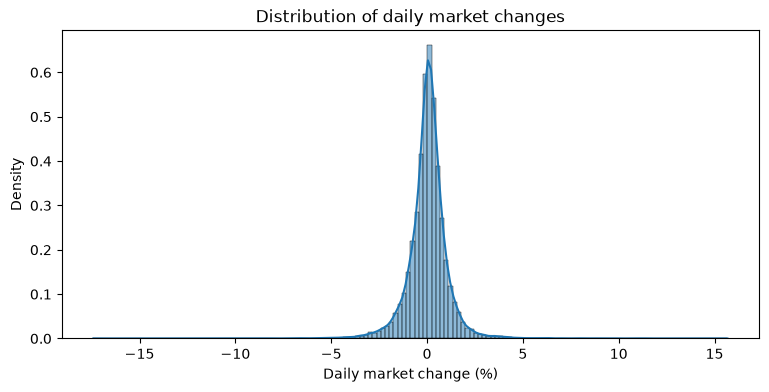

In [3]:
fig, ax = plt.subplots(figsize=(9, 4))
sns.histplot(data=df, x='market_return_pct', bins=150, stat='density', kde=True, ax=ax)
ax.set(xlabel='Daily market change (%)', title='Distribution of daily market changes')
plt.show()

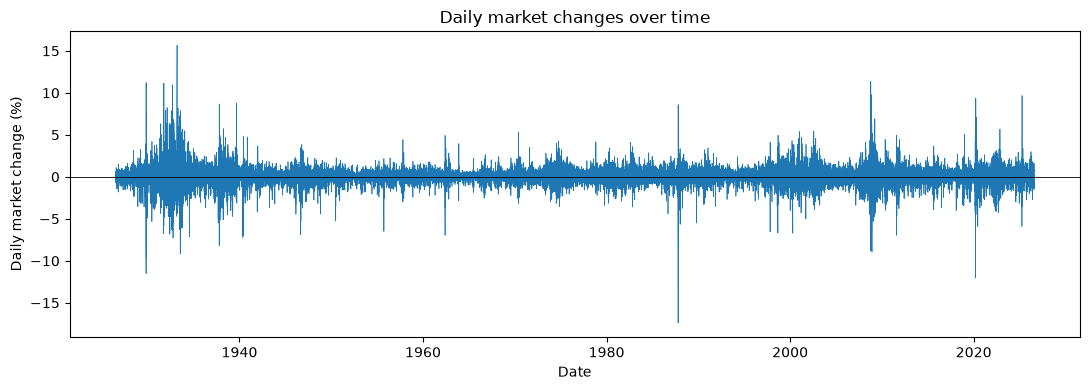

In [4]:
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(df['date'], df['market_return_pct'], linewidth=0.5)
ax.axhline(0, color='black', linewidth=0.6)
ax.set(xlabel='Date', ylabel='Daily market change (%)',
       title='Daily market changes over time')
fig.tight_layout()
plt.show()

### 1. Two States

- Start with two categories: **Up** for values greater than 0, and **Down (and flat)** for values less than or equal to 0. Create variables in your dataframe to capture the current and next value of `market_return_pct`.
- Pair today's category with the next trading day's category. Compute the joint PMF and marginals, and the conditional PMF. 
- Are up transitions more or less common than down transitions? 
- Are you more likely to transition to an Up day from a Down or Up day?

In [5]:
df['x_t'] = df['market_return_pct']
df['x_tp1'] = df['market_return_pct'].shift(-1)
df['up_t'] = np.where(df['x_t'] > 0, 'Up', 'Down')
df['up_tp1'] = df['up_t'].shift(-1)
two_df = df.dropna(subset=['x_tp1'])
print(f'{len(two_df):,} (today, next trading day) pairs')
display(two_df[['date', 'x_t', 'x_tp1', 'up_t', 'up_tp1']].head())

26,295 (today, next trading day) pairs


,date,x_t,x_tp1,up_t,up_tp1
0,1926-07-01,0.10,0.46,Up,Up
1,1926-07-02,0.46,0.18,Up,Up
2,1926-07-06,0.18,0.10,Up,Up
3,1926-07-07,0.10,0.23,Up,Up
4,1926-07-08,0.23,-0.70,Up,Down


In [6]:
two_counts = pd.crosstab(two_df['up_t'], two_df['up_tp1'], margins=True)
print('Transition counts:')
display(two_counts)
two_joint = pd.crosstab(two_df['up_t'], two_df['up_tp1'], normalize=True, margins=True)
print('Joint PMF (margins = marginal PMFs):')
display(two_joint.round(4))

Transition counts:


up_tp1,Down,Up,All
up_t,,,
Down,5909,5999,11908
Up,5999,8388,14387
All,11908,14387,26295


Joint PMF (margins = marginal PMFs):


up_tp1,Down,Up,All
up_t,,,
Down,0.2247,0.2281,0.4529
Up,0.2281,0.3190,0.5471
All,0.4529,0.5471,1.0000


In [7]:
two_cond = pd.crosstab(two_df['up_t'], two_df['up_tp1'], normalize='index')
print('Conditional PMF, pr[tomorrow | today] (rows sum to 1):')
display(two_cond.round(4))

Conditional PMF, pr[tomorrow | today] (rows sum to 1):


up_tp1,Down,Up
up_t,,
Down,0.4962,0.5038
Up,0.4170,0.5830


- A transition into an Up day is more common than a transition into a Down day at 54.71% . The single most common transition is Up → Up at 31.7%.
- You are more likely to transition to an Up day from an Up dat with P(Up/Up) = 58.3% versus P(Up/Down) = 50.38%.


### 2. Binning a Continuous Variable

Now keep the sign and a coarse measure of the size of a daily log return:

| Category | Daily log return (%) |
| --- | --- |
| Large loss | $r \leq -1$ |
| Small loss | $-1 < r \leq -0.1$ |
| Near zero | $-0.1 < r \leq 0.1$ |
| Small gain | $0.1 < r \leq 1$ |
| Large gain | $r > 1$ |

For example, −2 belongs to **Large loss**, 0.05 to **Near zero**, and 0.8 to **Small gain**. These cutoffs are choices for this exercise. Each interval includes its upper endpoint; `-np.inf` and `np.inf` let the outer intervals include any size loss or gain.

- `pd.cut` to group `market_return_pct` into the five categories above. How many days fall into each of the five bins? Which are the most or least common?
- Compute the joint PMF and marginals. Which transitions are most likely to occur? 
- Compute the conditional PMF. For each current state, which two future states are the most likely? Subjectively, how close is each row to a uniform mass function with probability .2 over each transition? Is it relatively easy or difficult to predict the next state?
- For each state, compute the conditional expectation of tomorrow's `market_return_pct`. Given the current state, what are the expected percent returns for tomorrow? How do the min and max values for tomorrow vary across states? Which states have the highest standard deviation for tomorrow's percent returns? Describe any patterns in the volatility you notice. Using `.groupby` and `.describe` is the easiest way to do this. 

In [8]:
bins = [-np.inf, -1, -0.1, 0.1, 1, np.inf]
labels = ['Large loss', 'Small loss', 'Near zero', 'Small gain', 'Large gain']
df['cat_t'] = pd.cut(df['x_t'], bins=bins, labels=labels)
df['cat_tp1'] = df['cat_t'].shift(-1)
five_df = df.dropna(subset=['x_tp1'])
cat_counts = df['cat_t'].value_counts().reindex(labels)
display(pd.DataFrame({'days': cat_counts, 'share': (cat_counts / cat_counts.sum()).round(4)}))

,days,share
cat_t,,
Large loss,2759,0.1049
Small loss,7452,0.2834
Near zero,3441,0.1309
Small gain,9785,0.3721
Large gain,2859,0.1087


- There are 9785 days for small gain, 7452 days for small loss, 3441 days for near zero, 2859 days for large gain, and 2759 days for large loss
- The most common bin is small gain and the least common bin is large loss

In [9]:
five_counts = pd.crosstab(five_df['cat_t'], five_df['cat_tp1'], margins=True)
five_joint = pd.crosstab(five_df['cat_t'], five_df['cat_tp1'], normalize=True, margins=True)
print('Joint PMF (margins = marginal PMFs):')
display(five_joint.round(4))

Joint PMF (margins = marginal PMFs):


cat_tp1,Large loss,Small loss,Near zero,Small gain,Large gain,All
cat_t,,,,,,
Large loss,0.0213,0.0272,0.0091,0.0278,0.0195,0.1049
Small loss,0.0354,0.0886,0.0342,0.0978,0.0274,0.2834
Near zero,0.0093,0.0420,0.0210,0.0493,0.0093,0.1309
Small gain,0.0250,0.1001,0.0550,0.1594,0.0326,0.3721
Large gain,0.0138,0.0255,0.0116,0.0378,0.0199,0.1087
All,0.1049,0.2834,0.1308,0.3721,0.1087,1.0000


- The most likely transitions are Small gain -> Small gain at 15.9%, Small gain -> Small loss at 10%, Small loss -> Small gain at 9.8%, and Small loss -> Small loss at 8.9%

In [10]:
five_cond = pd.crosstab(five_df['cat_t'], five_df['cat_tp1'], normalize='index')
print('Conditional PMF, pr[tomorrow | today] (rows sum to 1):')
display(five_cond.round(4))

Conditional PMF, pr[tomorrow | today] (rows sum to 1):


cat_tp1,Large loss,Small loss,Near zero,Small gain,Large gain
cat_t,,,,,
Large loss,0.2033,0.2592,0.0863,0.2650,0.1863
Small loss,0.1251,0.3128,0.1205,0.3450,0.0966
Near zero,0.0712,0.3208,0.1601,0.3769,0.0709
Small gain,0.0672,0.2689,0.1479,0.4285,0.0876
Large gain,0.1273,0.2347,0.1070,0.3477,0.1833


- For each current state, the two most likely next states are Small gain and Small loss.

- Large loss is closest to uniform with its probabilities (0.20, 0.26, 0.09, 0.27, 0.19) are mostly near 0.2. Large gain (0.13, 0.23, 0.11, 0.35, 0.18) and Small loss (0.13, 0.31, 0.12, 0.35, 0.10) are moderately close, with probabilities ranging from about 0.1 to 0.35.Near zero (0.07, 0.32, 0.16, 0.38, 0.07) and Small gain (0.07, 0.27, 0.15, 0.43, 0.09) are the farthest from uniform. They put most of their weight on small moves and very little (about 7%) on large losses.

- I think it is difficult to predict the next day because the best guess in every row is Small gain and it is correct at maximum 43% of the time. I think today state mostly tell us about the size of tomorrow's move.

In [11]:
five_next = five_df.groupby('cat_t', observed=True)['x_tp1'].describe()
display(five_next.round(3))

,count,mean,std,min,25%,50%,75%,max
cat_t,,,,,,,,
Large loss,2759.0,-0.038,1.721,-17.41,-0.79,-0.01,0.72,11.22
Small loss,7452.0,-0.044,1.010,-11.23,-0.53,0.01,0.45,11.36
Near zero,3441.0,0.015,0.826,-8.19,-0.35,0.03,0.42,5.49
Small gain,9784.0,0.107,0.832,-8.25,-0.25,0.12,0.50,8.67
Large gain,2859.0,0.163,1.384,-12.00,-0.37,0.15,0.73,15.67


Given the current state, what are the expected percent returns for tomorrow?

| Today | E[tomorrow's %] |
| --- | --- |
| Large loss | −0.038 |
| Small loss | −0.044 |
| Near zero | 0.015 |
| Small gain | 0.107 |
| Large gain | 0.163 |

- The extreme states of Large loss and Large gain will have the widest ranges in min and max.  After a Large loss, tomorrow ranged from −17.41% to +11.22%, which includes the worst day in the sample. After a Large gain, it ranged from −12.00% to +15.67%, which includes the best day.
- Large loss has the highest standard deviation at 1.72.
- For volatility pattern, I see that large loss and large gain are followed by more volatile days, and calm days are followed by calm days. Also, I see that losses raise next-day volatility more than gains of the same size. For standard deviation, Large loss (1.72) > Large gain (1.38), and Small loss (1.01) > Small gain (0.83).

### 3. Scaling up

The choice of five bins was arbitrary. For more realistic or complex models, we'd want to flexibly choose the number of bins. Instead of the five bins from above, we'll break the data into 21 equally spaced bins based on quantile; the qualitative results hold up for 11 or 71 or 101, but 21 is interpretable and easier to manage.

- Use `pd.qcut` to assign the data into 21 bins, and add that variable to the dataframe as `df[y_t]`. Use `.shift(-1)` to create `df[y_tp1]`. 
- Compute the joint PMF. Plot it as a heatmap. Do you see any obvious patterns? Explain. Try subtracting 1/21**2 from the PMF before plotting it, to normalize away the uniform PMF, and see systematic deviations from uniformly random behavior.
- Compute the conditional PMF. Plot it as a heatmap. Do you see any obvious patterns? Explain. Try subtracting 1/21 from the PMF before plotting it, to normalize away the uniform PMF, and see systematic deviations from uniformly random transitions.
- For each bin, compute the next day's minimum, mean, and maximum values. Plots these as lines on a graph against the bins. Do you see any obvious patterns? Explain. 
- For each bin, compute the next day's standard deviation, and plot it as a line graph against the bins. Do you see any obvious patterns? Explain. 
- How easy is it to predict the market?

In [12]:
n_bins = 21
df['y_t'] = pd.qcut(df['x_t'], q=n_bins, labels=False, duplicates='drop')
df['y_tp1'] = df['y_t'].shift(-1)
q_df = df.dropna(subset=['y_tp1']).astype({'y_tp1': int})
bin_summary = df.groupby('y_t')['x_t'].agg(['count', 'min', 'max'])
print(bin_summary)

     count    min    max
y_t                     
0     1255 -17.41  -1.61
1     1253  -1.61  -1.07
2     1286  -1.06  -0.78
3     1280  -0.78  -0.57
4     1230  -0.56  -0.42
5     1226  -0.41  -0.30
6     1371  -0.29  -0.19
7     1206  -0.18  -0.11
8     1198  -0.11  -0.03
9     1331  -0.03   0.04
10    1210   0.05   0.11
11    1223   0.11   0.18
12    1294   0.19   0.26
13    1223   0.27   0.34
14    1310   0.35   0.44
15    1193   0.45   0.54
16    1211   0.55   0.67
17    1283   0.68   0.84
18    1225   0.84   1.09
19    1250   1.10   1.55
20    1238   1.56  15.67


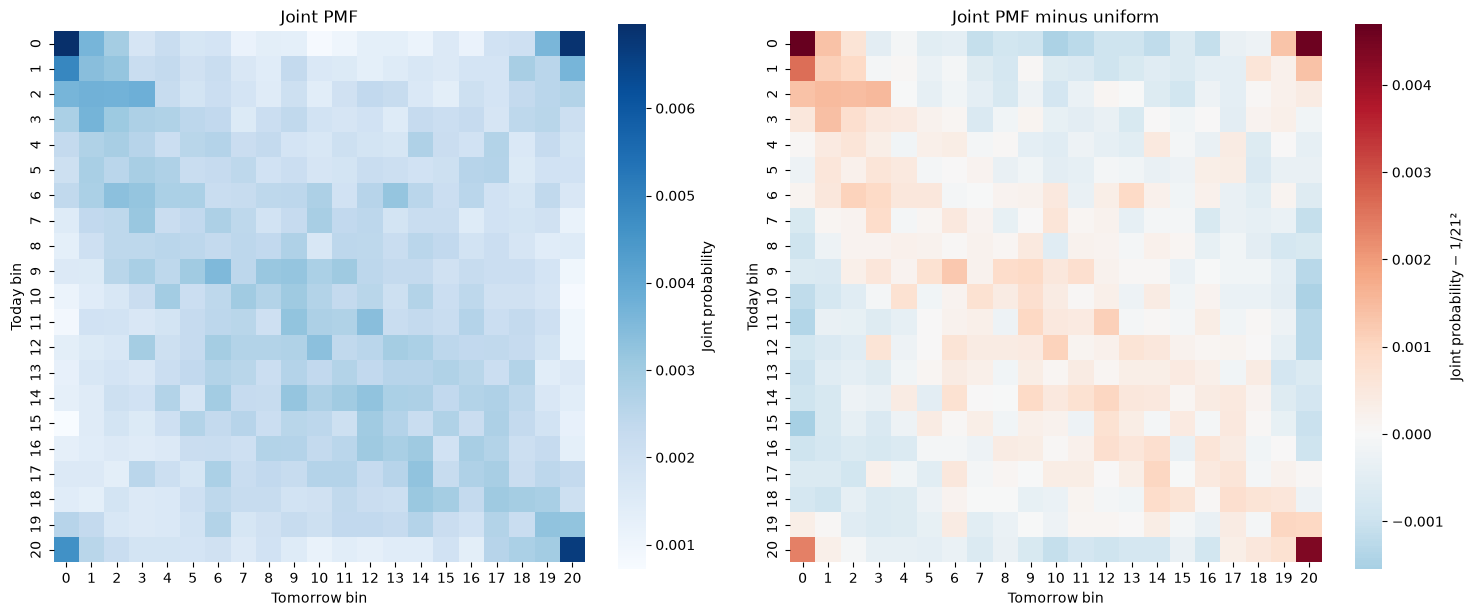

In [13]:
q_joint = pd.crosstab(q_df['y_t'], q_df['y_tp1'], normalize=True)
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
sns.heatmap(q_joint, cmap='Blues', square=True,
            cbar_kws={'label': 'Joint probability'}, ax=axes[0])
axes[0].set(title='Joint PMF', xlabel='Tomorrow bin', ylabel='Today bin')
sns.heatmap(q_joint - 1 / n_bins**2, cmap='RdBu_r', center=0, square=True,
            cbar_kws={'label': 'Joint probability − 1/21²'}, ax=axes[1])
axes[1].set(title='Joint PMF minus uniform', xlabel='Tomorrow bin', ylabel='Today bin')
fig.tight_layout()
plt.show()

For Joint PMF's heatmap, several patterns I have noticed:
- Corners: All four corners are dark red. Big days, up or down, tend to be followed by more big days, in either direction. This is volatility clustering.
- Edges: The middle stretches of the outer rows and columns are blue. After a big day, a quiet day is less likely than usual.
- Center: There's a faint red streak along the middle of the diagonal, so quiet days tend to follow quiet days. There's also a small red patch in the top-left: losses tend to follow losses, like during a sell-off.

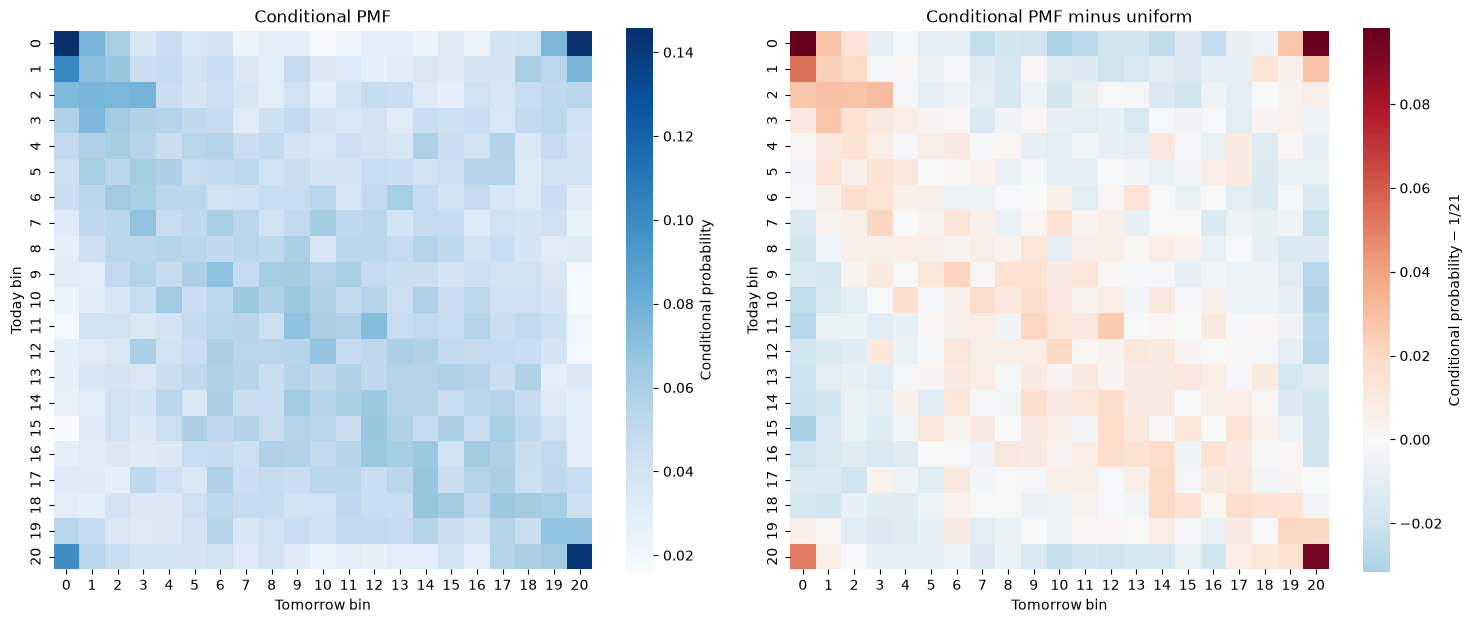

In [14]:
q_cond = pd.crosstab(q_df['y_t'], q_df['y_tp1'], normalize='index')
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
sns.heatmap(q_cond, cmap='Blues', square=True,
            cbar_kws={'label': 'Conditional probability'}, ax=axes[0])
axes[0].set(title='Conditional PMF', xlabel='Tomorrow bin', ylabel='Today bin')
sns.heatmap(q_cond - 1 / n_bins, cmap='RdBu_r', center=0, square=True,
            cbar_kws={'label': 'Conditional probability − 1/21'}, ax=axes[1])
axes[1].set(title='Conditional PMF minus uniform', xlabel='Tomorrow bin', ylabel='Today bin')
fig.tight_layout()
plt.show()

For Conditional PMF's heatmap, this looks almost the same as the joint PMF, because every bin has about the same number of days. The difference is that each row now shows where tomorrow tends to go, given today.

- After a big day (top and bottom rows), the corners are dark red again because a big move is likely to be followed by another big move, up or down. Quiet days are less likely than usual.
- After a quiet day (middle rows), the middle is slightly red, so a quiet day tends to follow.
- For everywhere else, the colors are pale. Today's bin doesn't change much about tomorrow.

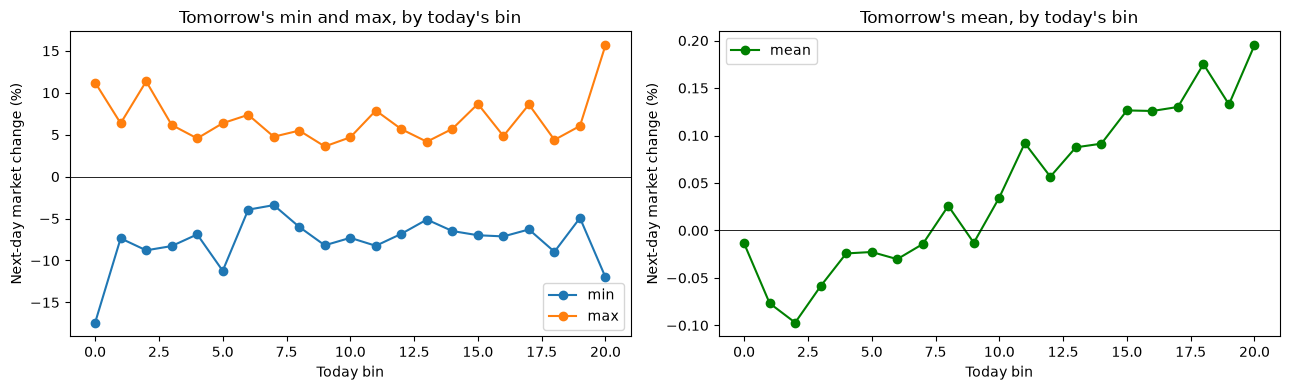

In [15]:
q_next = q_df.groupby('y_t')['x_tp1'].agg(['min', 'mean', 'max', 'std'])
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for stat in ['min', 'max']:
    axes[0].plot(q_next.index, q_next[stat], marker='o', label=stat)
axes[0].axhline(0, color='black', linewidth=0.6)
axes[0].set(title="Tomorrow's min and max, by today's bin",
            xlabel='Today bin', ylabel='Next-day market change (%)')
axes[0].legend()
axes[1].plot(q_next.index, q_next['mean'], marker='o', color='green', label='mean')
axes[1].axhline(0, color='black', linewidth=0.6)
axes[1].set(title="Tomorrow's mean, by today's bin",
            xlabel='Today bin', ylabel='Next-day market change (%)')
axes[1].legend()
fig.tight_layout()
plt.show()

Patterns in min, mean, and max:

- Min and max: the range is widest at both ends. The worst and best days in the whole sample both come right after extreme days. In the middle bins the range is narrower. These lines jump around a lot, though, because each point is just one day.
- Mean: it creeps up as you move from losses to gains, so a better day today tends to go with a slightly better day tomorrow. The exception is bin 0: after the very worst days, the average bounces back toward zero, maybe because the market partly recovers after a crash.
- The big picture: the mean barely moves compared with the min and max. Tomorrow's average hardly depends on today, but how wild tomorrow can get does.

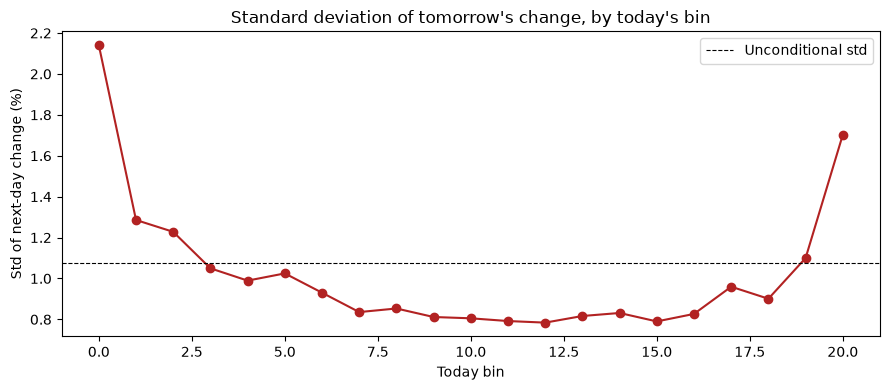

In [16]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(q_next.index, q_next['std'], marker='o', color='firebrick')
ax.axhline(q_df['x_tp1'].std(), color='black', linestyle='--', linewidth=0.8,
           label='Unconditional std')
ax.set(title="Standard deviation of tomorrow's change, by today's bin",
       xlabel='Today bin', ylabel='Std of next-day change (%)')
ax.legend()
fig.tight_layout()
plt.show()

- The next-day standard deviation is 2.14% after bin 0 and 1.70% after bin 20, compared with only about 0.79–0.81% after the middle bins (9–12). The curve is also asymmetric. Similar with the 5 bins in Question 2, the standard deviation is higher on the loss side than on the gain side and large losses predict bigger moves than large gains. 

- I think it is very difficult to predict the market. In the two-state version, an Up day only increase the chance of the next Up day from 50% to 58%. With more bins it doesn't get better: whatever happened today, my best guess for tomorrow is still wrong more often than it's right. Tomorrow's average return barely changes with today's bin, either. I think what is predictable is how much the market moves. Big days tend to be followed by big days, quiet days by quiet days, and a bad day shakes things up more than a good one. So this model won't tell you where the market's headed, but it does give you a decent sense of how bumpy tomorrow might be.